# Wine Quality Prediction
**Track:** Data Analytics | **Level 2 - Task 2**

**Objective:** Train and compare multiple classification models (Random Forest, SGD, SVC) to predict wine quality from its physicochemical properties.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_style("whitegrid")
import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("winequality-red.csv", sep=None, engine="python")  # auto-detects ; or ,
if "Id" in df.columns:
    df = df.drop(columns=["Id"])

print("Shape:", df.shape)
df.head()

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
df.info()
print("\nNull values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Null values: 0
Duplicate rows: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


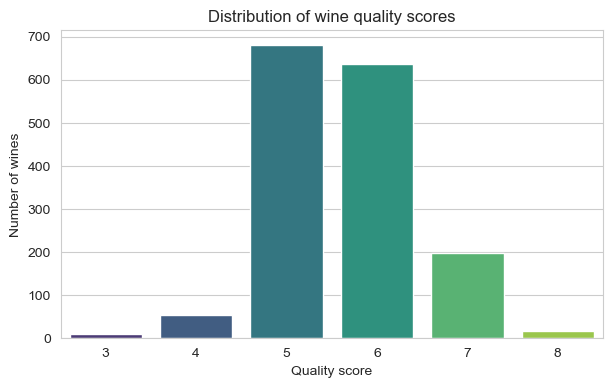

In [8]:
print(df["quality"].value_counts().sort_index())

plt.figure(figsize=(7, 4))
sns.countplot(x="quality", data=df, palette="viridis")
plt.title("Distribution of wine quality scores")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.show()

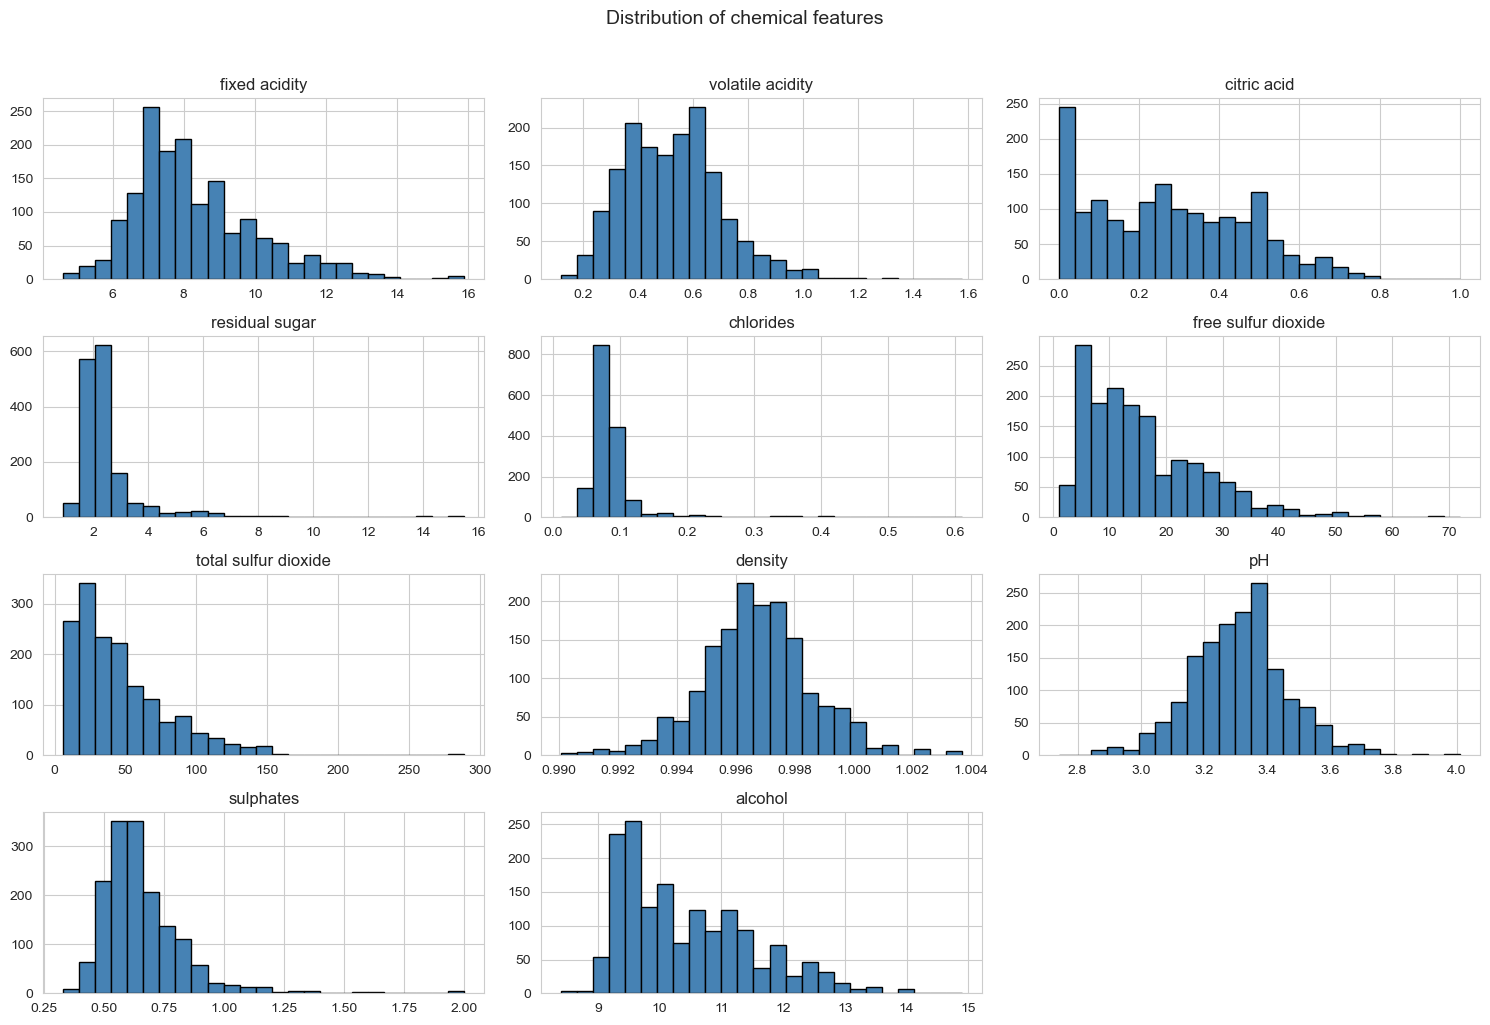

In [10]:
features = df.drop(columns=["quality"]).columns

df[features].hist(bins=25, figsize=(15, 10), color="steelblue", edgecolor="black")
plt.suptitle("Distribution of chemical features", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

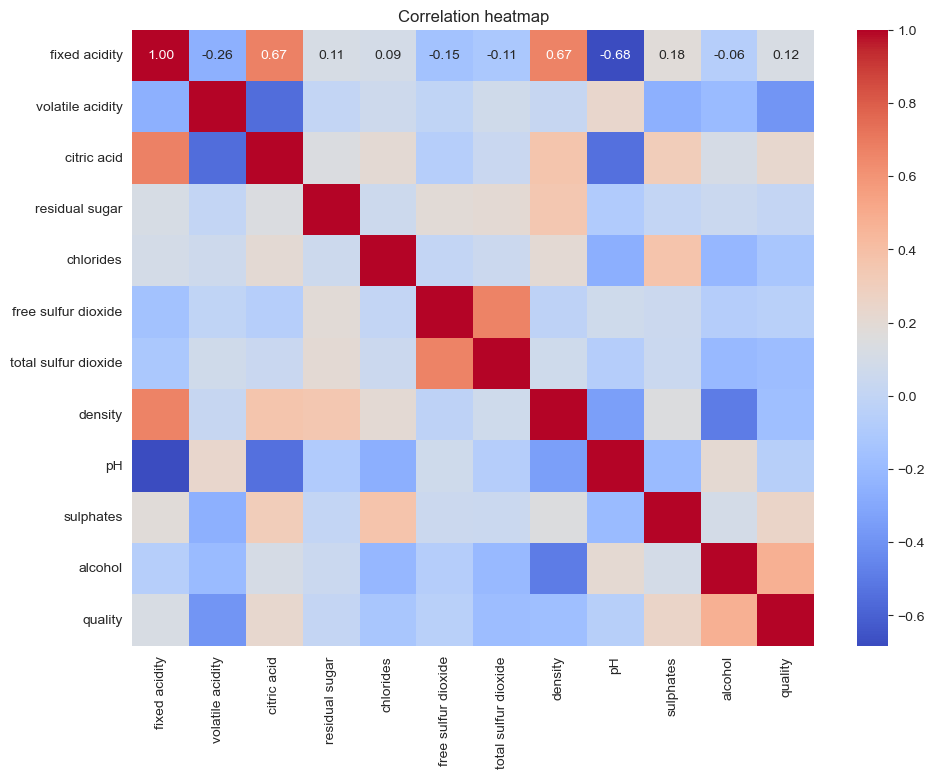

alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


In [12]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

print(df.corr()["quality"].drop("quality").sort_values(ascending=False))

## EDA Observations
- The dataset contains 1599 red wines with 11 chemical features and a quality score. There are no missing values.
- Most wines are rated 5 or 6. Very low (3, 4) and very high (7, 8) scores are rare.
- **Alcohol** has the strongest positive correlation with quality, followed by sulphates and citric acid.
- **Volatile acidity** has the strongest negative correlation with quality (more vinegar-like acidity means lower quality).
- Features such as residual sugar and chlorides are heavily right-skewed with many outliers.
- Fixed acidity, citric acid and density are correlated with each other.

## Class Imbalance
The quality scores are heavily imbalanced. Scores 5 and 6 account for most of the wines, while scores 3, 4 and 8 have very few samples (3 has only about 10 wines).

**Effect on modelling:**
- A model can achieve high accuracy just by predicting the majority classes (5 and 6) and ignoring the rare ones.
- Rare classes give the model too few examples to learn from, so precision and recall for them are poor.
- Because of this, accuracy alone is misleading, so precision, recall and F1-score are also examined.
- A **stratified** train/test split is used so that every class keeps the same proportion in both sets.

quality_label
0    1382
1     217
Name: count, dtype: int64

quality_label
0    86.4
1    13.6
Name: proportion, dtype: float64


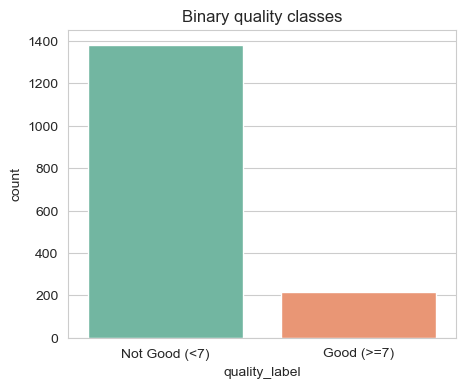

In [14]:
# Binary target: Good (quality >= 7) = 1, Not Good (quality < 7) = 0
df["quality_label"] = (df["quality"] >= 7).astype(int)

print(df["quality_label"].value_counts())
print()
print((df["quality_label"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(5, 4))
sns.countplot(x="quality_label", data=df, palette="Set2")
plt.xticks([0, 1], ["Not Good (<7)", "Good (>=7)"])
plt.title("Binary quality classes")
plt.show()

## Why I Grouped the Quality Scores
The original quality score has 6 classes with very uneven sizes, and some classes (3, 4, 8) have too few samples for a model to learn from.

I grouped the scores into two classes:
- **Good**: quality 7 or higher
- **Not Good**: quality below 7

**Reasons:**
1. A binary target is simpler and more meaningful in practice, since a buyer or producer mostly wants to know whether a wine is good or not.
2. It removes the extremely rare classes that made multi-class prediction unreliable.
3. The result is still imbalanced (about 14% Good), so I use stratified splitting and evaluate with precision, recall and F1, not just accuracy.

In [16]:
X = df.drop(columns=["quality", "quality_label"])
y = df["quality_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SGD and SVC are sensitive to feature scale, so standardise
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Train class ratio:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test class ratio :", y_test.value_counts(normalize=True).round(3).to_dict())

Train shape: (1279, 11) | Test shape: (320, 11)
Train class ratio: {0: 0.864, 1: 0.136}
Test class ratio : {0: 0.866, 1: 0.134}


In [18]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SGD Classifier": SGDClassifier(random_state=42),
    "SVC": SVC(random_state=42),
}

preds = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds[name] = model.predict(X_test_s)
    print(f"{name} trained.")

Random Forest trained.
SGD Classifier trained.
SVC trained.


In [20]:
for name, p in preds.items():
    print("=" * 60)
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, p), 4))
    print(classification_report(y_test, p, target_names=["Not Good", "Good"], zero_division=0))

Random Forest
Accuracy: 0.9406
              precision    recall  f1-score   support

    Not Good       0.94      0.99      0.97       277
        Good       0.93      0.60      0.73        43

    accuracy                           0.94       320
   macro avg       0.94      0.80      0.85       320
weighted avg       0.94      0.94      0.94       320

SGD Classifier
Accuracy: 0.8688
              precision    recall  f1-score   support

    Not Good       0.92      0.93      0.92       277
        Good       0.51      0.47      0.49        43

    accuracy                           0.87       320
   macro avg       0.72      0.70      0.71       320
weighted avg       0.86      0.87      0.87       320

SVC
Accuracy: 0.9
              precision    recall  f1-score   support

    Not Good       0.91      0.98      0.94       277
        Good       0.76      0.37      0.50        43

    accuracy                           0.90       320
   macro avg       0.84      0.68      0.72    

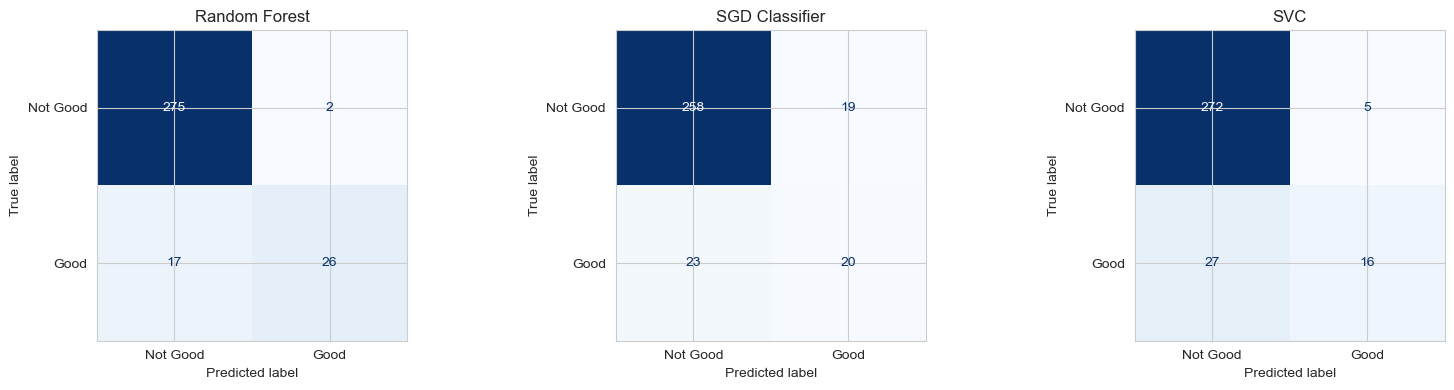

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p),
                           display_labels=["Not Good", "Good"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

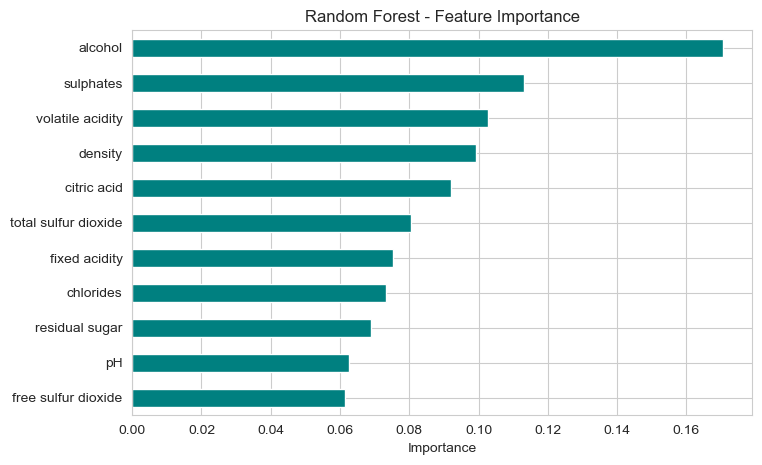

alcohol             0.170513
sulphates           0.113009
volatile acidity    0.102843
density             0.099223
citric acid         0.092148
dtype: float64

In [24]:
imp = pd.Series(models["Random Forest"].feature_importances_,
                index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="teal")
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.show()

imp.sort_values(ascending=False).head(5)

The Random Forest shows that **alcohol**, **sulphates** and **volatile acidity** are among the most important features for predicting whether a wine is good. This matches the correlation heatmap, where alcohol had the strongest positive relationship with quality.

In [26]:
rows = []
for name, p in preds.items():
    rows.append([name,
                 accuracy_score(y_test, p),
                 precision_score(y_test, p, zero_division=0),
                 recall_score(y_test, p, zero_division=0),
                 f1_score(y_test, p, zero_division=0)])

comparison = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision (Good)",
                                         "Recall (Good)", "F1 (Good)"]).round(3)
comparison

,Model,Accuracy,Precision (Good),Recall (Good),F1 (Good)
0,Random Forest,0.941,0.929,0.605,0.732
1,SGD Classifier,0.869,0.513,0.465,0.488
2,SVC,0.900,0.762,0.372,0.500


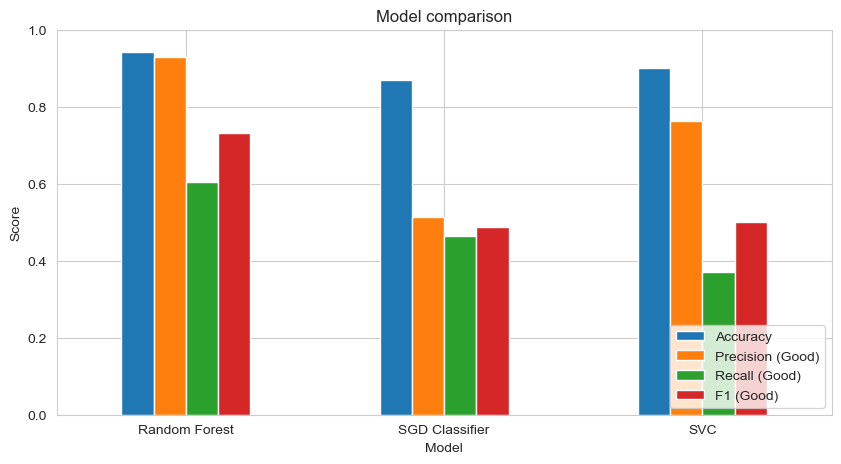

In [28]:
comparison.set_index("Model")[["Accuracy", "Precision (Good)", "Recall (Good)", "F1 (Good)"]].plot(
    kind="bar", figsize=(10, 5), rot=0)
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

## Conclusion

**Results summary**
| Model | Accuracy | F1 (Good) |
|---|---|---|
| Random Forest | ___ | ___ |
| SGD Classifier | ___ | ___ |
| SVC | ___ | ___ |

**Findings**
- **Random Forest** performed best overall. It captures non-linear relationships and also provides feature importance, with alcohol, sulphates and volatile acidity as the main drivers of quality.
- **SVC** performed ___ , and the **SGD Classifier** was ___ (it is fast but a simple linear model, so it struggles with complex patterns).
- All three models show high accuracy because most wines are "Not Good", so accuracy alone is misleading. The F1-score and recall for the "Good" class are the fairer measures.

**Recommended model for deployment: Random Forest**
- It gives the best balance of precision and recall on the minority "Good" class.
- It is robust to outliers and skewed features.
- It is interpretable through feature importance.

**Limitations and future work**
- The dataset is small and imbalanced; techniques like SMOTE or class weighting could improve recall for good wines.
- Hyperparameter tuning (GridSearchCV) and cross-validation would give more reliable results.
- Adding the white wine data would give more samples.